# AP 155 Lab Exercise
---
## Exercise 11: Fourier transform

_Instructions_:
- **Report**: See instructions in Problems 1,2,3
- **Code**: Complete the code and ensure it is functional, error-free, readable, and efficient (where needed). Include concise Markdown documentation highlighting the critical steps of your algorithm for each problem.

### Student Information
- _Full Name (Last Name, First Name)_: Hernando, Claire Marie 
- _Student No._: 2024-12904
- _Section_: THU-TX-1

### Grading Information (c/o Lab Instructor)
- [Rubrics description link](https://drive.google.com/file/d/1BMSlPot2Mc7XLu0eo4S8I8gLBsIadbCL/view)

| Criteria | Score | Subtotal |
| --- | --- | --- |
| Report figure | XX | 20 |
| Report discussion | XX | 20|
| Code readability | XX | 20 |
| Code efficiency | XX | 20 | 
| Code appropriateness  | XX | 20 | 
| **TOTAL** | XXX | 100 |

_Date and Time Scored (MM/DD/YYYY HH:MM AM/PM):_ 

---
## Section 1: Report

### Report figure

#### Problem 1 Figures

![Fourier Transform Analysis of Triangle Waveform](triangle_one.png) <img src="../Claire/Exercise 10/triangle_one.png" width=45%>
***Figure 1** shows the plot of the Fourier Transform analysis of the Triangle Waveform plotted using scipy's signal.sawtooth.*

![Fourier Transform Analysis of Triangle Waveform with its Varying Frequencies](triangle_var_freq.png) <img src="../Claire/Exercise 10/triangle_var_freq.png" width=45%>
***Figure 2** shows the plot of the Fourier Transform analysis of the Triangle Waveform with its varying frequencies at 2.0 Hz, 3.0 Hz, 5.0 Hz, and 10.0 Hz.*

![Fourier Transform Analysis of Triangle Waveform with its Varying Width Parameters](triangle_var_width.png) <img src="../Claire/Exercise 10/triangle_var_width.png" width=45%>
***Figure 3** shows the plot of the Fourier Transform analysis of the Triangle Waveform with its varying width parameters to show the ramp (width=1.0), reversed ramp (width=0.0), and symmetrical triangle wave (width=0.5).*

![Fourier Transform Analysis of Gaussian Waveform with Varying Sigma](gaussian.png) <img src="../Claire/Exercise 10/gaussian.png" width=45%>
***Figure 4** shows the plot of the Fourier Transform analysis of the Gaussian waveform with varying $\sigma$ at 0.5, 1.0, and 2.0.*

#### Problem 2 Figure

![Plot of the Time Domain of the Original vs. Recovered Signal](orig_vs_recovered.png) <img src="../Claire/Exercise 10/orig_vs_recovered.png" width=45%>
***Figure 5** shows the plot of the time domain of the original signal compared to the recovered signal using np.fft.ifft.*

#### Problem 3 Figures

![Plot of the Time Domain of the Aliased vs. Unaliased Sine Wave](aliased_vs_unaliased.png) <img src="../Claire/Exercise 10/aliased_vs_unaliased.png" width=45%>
***Figure 6** shows the plot of the time domain of the aliased sine wave compared to the unaliased sine wave using aliasing techniques.*

![Plot of the Fourier Transform Comparison of the Aliased vs. Unaliased Waveform](ft_aliased_vs_unaliased.png) <img src="../Claire/Exercise 10/ft_aliased_vs_unaliased.png" width=45%>
***Figure 7** shows the plot of the Fourier Transform comparing the aliased and the unaliased waveforms.*

### Report discussion

**1.) 2-3 sentences explaining how changing the shape of the input signal affects it transform. Ex: for the Gaussian waveform, how does it Fourier transform change based on increasing or decreasing sigma?**

Changing the shape of the input signal has an inverse effect on its Fourier transform due to the scaling and uncertainty properties of Fourier analysis. For the case of the Gaussian waveform, as shown in Figure 4, as the standard deviation $\sigma$ increases, the signal becomes wider in time, causing the frequency-domain magnitude spectrum to become narrower and sharper. Likewise, since smaller $\sigma$ values yield lower peak magnitudes, their frequency spectra decay and drop below the noise threshold much faster, wherein smaller values show very short phase line or restricted strictly to the center, while larger values show flat phase line spanning across a much wider range of frequencies before hitting the noise floor. 

**2.) Try running the procedure with a lower number of N (N<25000). What does lowering N do to the original signal? Will I still be able to recover that original signal if I add the noise below? Is there a limit of N to which I can recover the signal well? Why?**

Running the procedure with a lower value of $N$ reduces the time-domain sampling density and shortens the total observation window $T$, degrading the frequency resolution characterized by $freqs$ using $np.fft.fftfreq$, thereby causing the peaks to widen significantly. Also, it is still possible to recover the signal at lower $N$, but there is already a strict lower limit for recovering the original signal to be possible. This is because at very low values of $N$, broadened signal peaks drop so low that they blend into the random noise floor, and when this happens, the threshold filter can no longer tell the difference between the signal and the noise, causing the IFFT to fail in reconstructing the waveform. 

**3.) Explain the report figure. Note the frequency of the signal you wanted to sample, the sampling frequencies used for the aliased and the non-aliased wave.**

Figures 6 and 7 show the phenomenon of signal aliasing using a continuous sine wave sampled at two different rates over a total duration of $T = 10s$. 

The **unaliased wave**, sampled at $f_s = 100\text{ Hz}$ ($n = 1000$), satisfies the Nyquist criterion ($f_s > 2f_{\text{signal}}$). Consequently, Figure 6 accurately traces the time-domain waveform, and Figure 7 correctly resolves the spectral peak at $\pm 2.1\text{ Hz}$. 

Meanwhile, the **aliased wave**, sampled at $f_s = 2.5\text{ Hz}$ ($n = 25$), severely violates the Nyquist limit of 1.25 Hz. This then causes geometric distortion in the time domain, as shown in Figure 6. In the frequency domain, Figure 7 shows that frequency folding occurs because the sampling interval cannot resolve the rapid oscillations, forcing the spectral peak to incorrectly manifest at $\vert{}f_s - f_{\text{signal}}\vert{} = 0.4\text{ Hz}$, successfully illustrating sampling constraints in digital signal processing.

### Other comments
- For my report discussion, I followed the number of sentences required in items 1 and 2, and the usualy 150-word-limit for item 3.


---
## Section 2: Code

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import math
from scipy import signal

### Problem 1: Exploring FT of varying waveforms

Given the waveforms from the pool below, produce a $1\times3$ plot containing the following: 
1) the signal, with its variations, 
2) the magnitude of its Fourier transform, and 
3) the phase information of the transform (up to you if unwrapped or not). 
    
Discussion: 2-3 sentences explaining how changing the shape of the input signal affects it transform. 
Ex: for the Gaussian waveform, how does it Fourier transform change based on increasing or decreasing sigma?

Waveforms you can try (prefarably non-sinusoidal):
- Square wave (both single and periodic)
- Triangle wave (sawtooth, ramp, reverse ramp)
- Gaussian function (vary sigma)
- Finite-time sinusoid
- Gaussian wave packet
- Dirac-delta 

In [2]:
# Setting parameters 
N = 500
t = np.linspace(0, 1, N, endpoint=False)
dt = t[1] - t[0]
signal_freq = 3.0
freqs = np.fft.fftfreq(N, dt)

# 1. The Signal
nonsinu_signal = signal.sawtooth(2 * np.pi * signal_freq * t) # Change waveform type here

# 2. The Magnitude of its Fourier Transform
signal_ft = np.fft.fft(nonsinu_signal)
mag_ft = np.abs(signal_ft)

# 3. The Phase Information of the Transform (unwrapped)
phase_ft = np.angle(signal_ft)
phase_ft_unwrapped = np.unwrap(phase_ft) # comment this if we want it wrapped

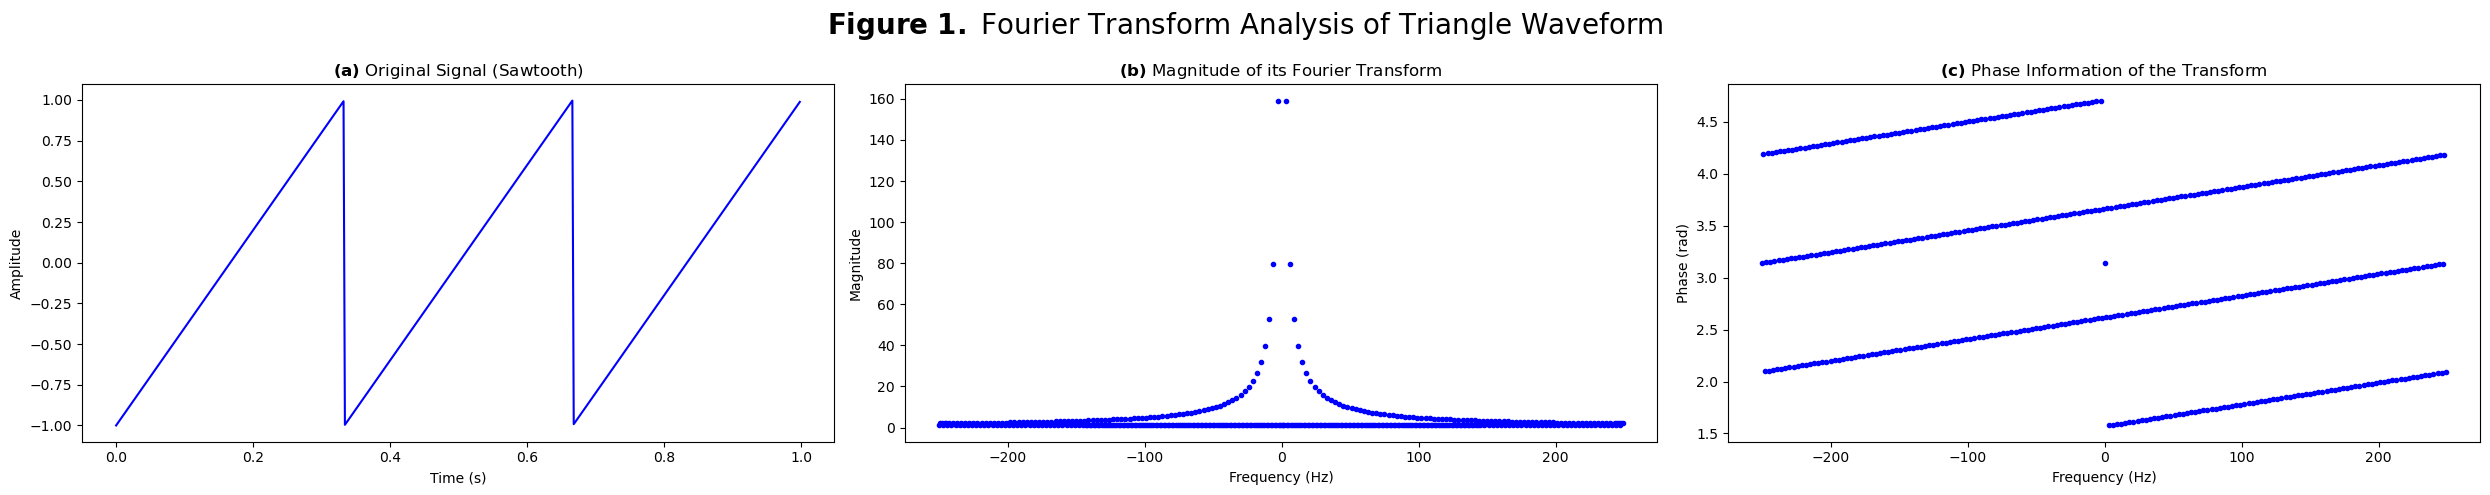

In [3]:
# Plotting into a 1x3 subplot 
fig, ax = plt.subplots(1, 3, figsize=(25, 5))

ax[0].plot(t, nonsinu_signal, color="blue")
ax[0].set_title(r"$\bf{(a)}$ Original Signal (Sawtooth)")
ax[0].set_xlabel("Time (s)")
ax[0].set_ylabel("Amplitude")

ax[1].plot(freqs, mag_ft, ".", color="blue")
ax[1].set_title(r"$\bf{(b)}$ Magnitude of its Fourier Transform")
ax[1].set_xlabel("Frequency (Hz)")
ax[1].set_ylabel("Magnitude")

ax[2].plot(freqs, phase_ft_unwrapped, ".", color="blue") # Use phase_ft if we want wrapped
ax[2].set_title(r"$\bf{(c)}$ Phase Information of the Transform")
ax[2].set_xlabel("Frequency (Hz)")
ax[2].set_ylabel("Phase (rad)")

plt.suptitle(r"$\bf{Figure\ 1.}$ Fourier Transform Analysis of Triangle Waveform", fontsize=20)

plt.tight_layout()
plt.savefig("triangle_one.png", dpi=150)
plt.show()

Now, I tried to add variations by varying the frequencies of the signal.

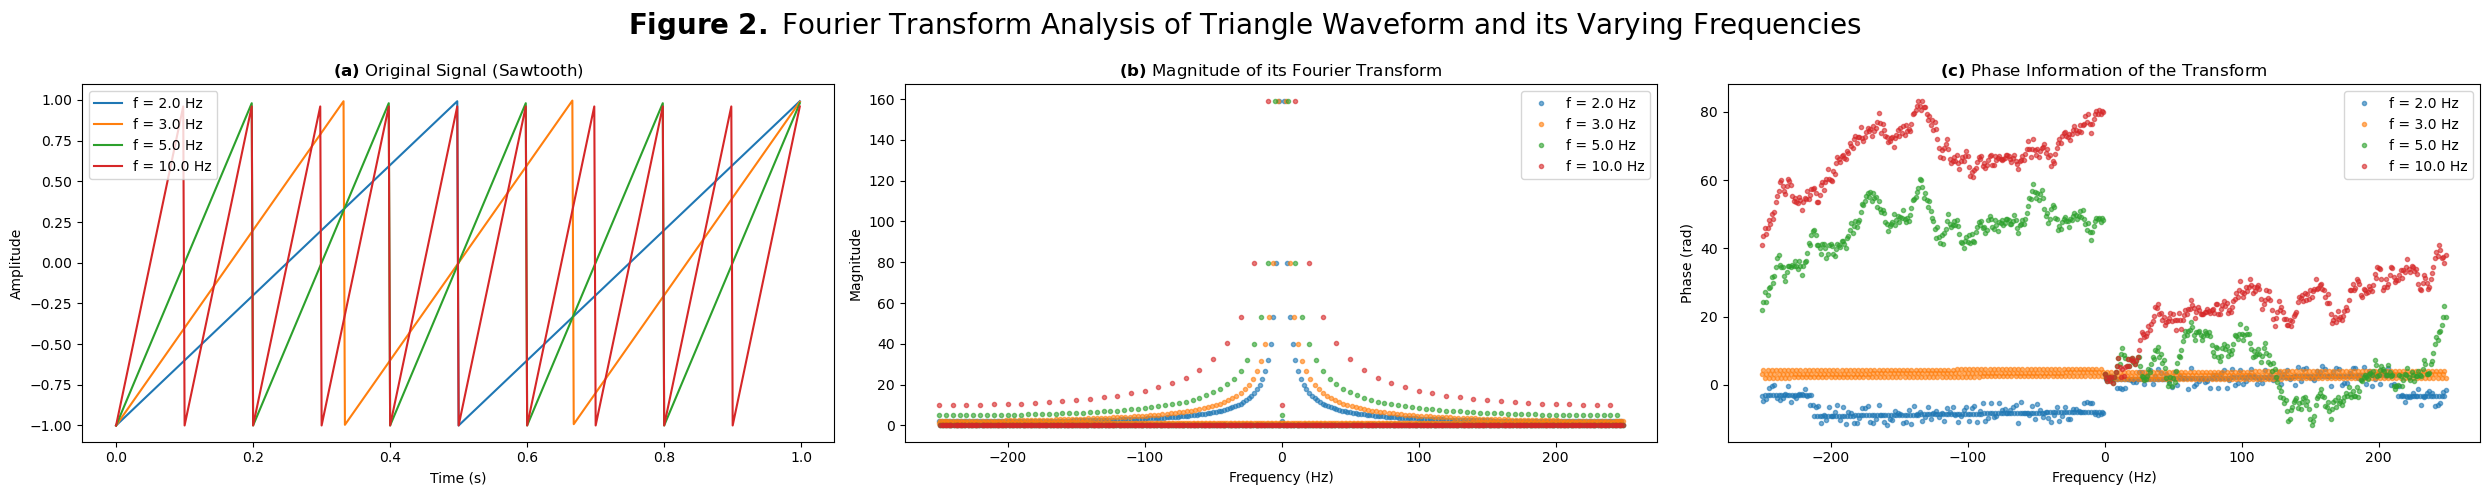

In [4]:
# Plotting using different frequency variations 
import numpy as np
import matplotlib.pyplot as plt
import math 
from scipy import signal 

# Setting parameters 
N = 500
t = np.linspace(0, 1, N, endpoint=False)
dt = t[1] - t[0]
freqs = np.fft.fftfreq(N, dt)

# Defining frequency variations to explore 
signal_freq_var = [2.0, 3.0, 5.0, 10.0]

# Plotting into a 1x3 subplot
fig, ax = plt.subplots(1, 3, figsize=(25,5))

for f in signal_freq_var:
    # 1. The Signal, with its variations 
    nonsinu_signal = signal.sawtooth(2 * np.pi * f * t)

    # 2. The Magnitude of its Fourier Transform
    signal_ft = np.fft.fft(nonsinu_signal)
    mag_ft = np.abs(signal_ft)

    # 3. The Phase Information of the Transform (unwrapped)
    phase_ft = np.angle(signal_ft)
    phase_ft_unwrapped = np.unwrap(phase_ft) # comment this if we want it wrapped

    # Plotting the variations on the same row for comparison
    ax[0].plot(t, nonsinu_signal, label=f'f = {f} Hz')
    ax[1].plot(freqs, mag_ft, ".", alpha=0.6, label=f'f = {f} Hz')
    ax[2].plot(freqs, phase_ft_unwrapped, ".", alpha=0.6, label=f'f = {f} Hz') # Use phase_ft if we want wrapped

# Formatting the subplots 
ax[0].set_title(r"$\bf{(a)}$ Original Signal (Sawtooth)")
ax[0].set_xlabel("Time (s)")
ax[0].set_ylabel("Amplitude")
ax[0].legend()

ax[1].set_title(r"$\bf{(b)}$ Magnitude of its Fourier Transform")
ax[1].set_xlabel("Frequency (Hz)")
ax[1].set_ylabel("Magnitude")
ax[1].legend()

ax[2].set_title(r"$\bf{(c)}$ Phase Information of the Transform")
ax[2].set_xlabel("Frequency (Hz)")
ax[2].set_ylabel("Phase (rad)")
ax[2].legend()

plt.suptitle(r"$\bf{Figure\ 2.}$ Fourier Transform Analysis of Triangle Waveform and its Varying Frequencies", fontsize=20)

plt.tight_layout()
plt.savefig("triangle_var_freq.png", dpi=150)
plt.show()

Now, let's try showing the ramp, reverse ramp, and symmetric variations of the triangle waveform. To do this, we need to adjust the **width parameters** of the sawtooth wave, the fraction of the total period where the signal reaches its peak/rises, using scipy function, wherein:

- **width = 0.0:** Reverse Ramp (falls the whole time, then rises) 
- **width = 0.5:** Symmetrical Triangle Wave (rises for half the cycle, then falls for the other half)
- **width = 1.0:** Standard Ramp (rises the whole time, then drops instantly)

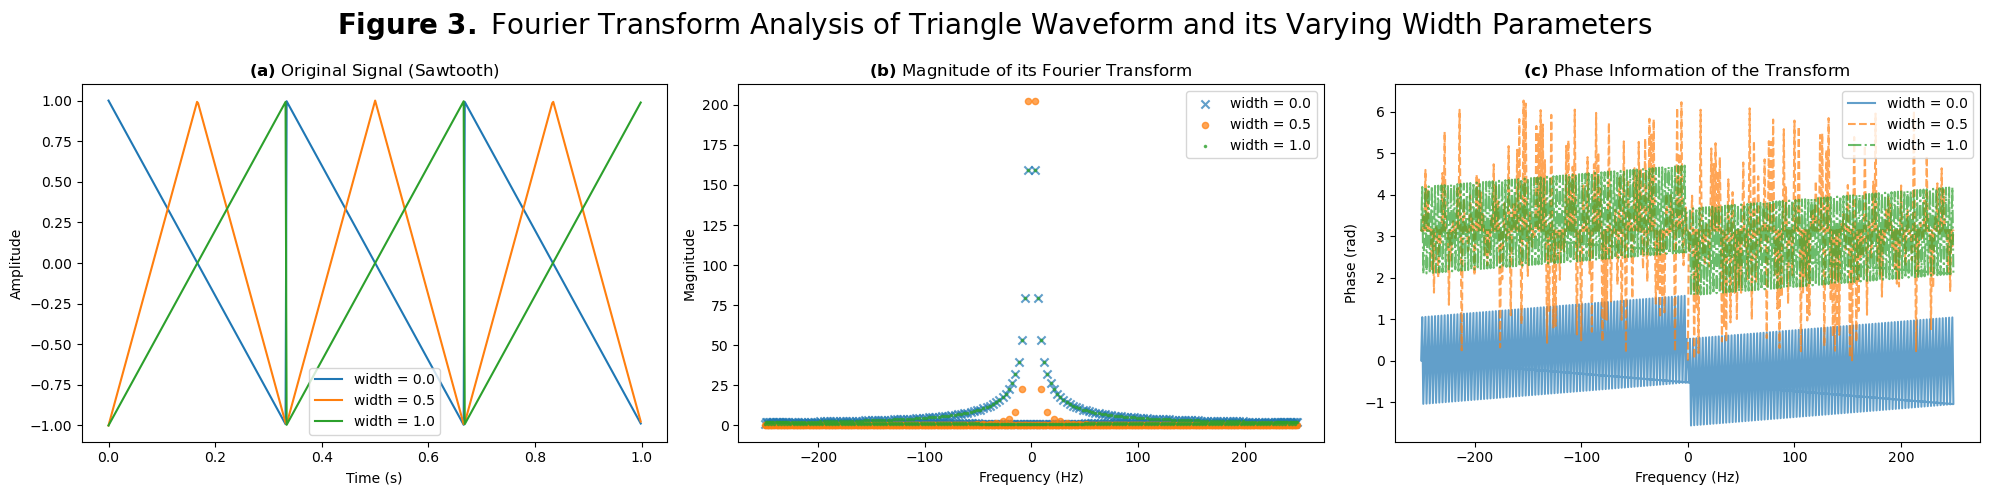

In [7]:
import numpy as np
import matplotlib.pyplot as plt
import math
from scipy import signal

# Setting parameters
N = 500
t = np.linspace(0, 1, N, endpoint=False)
signal_freq = 3.0
dt = t[1] - t[0]
freqs = np.fft.fftfreq(N, dt)

# Plotting into a 1x3 subplot
fig, ax = plt.subplots(1, 3, figsize=(20, 5))

# Defining width variations to explore
widths = [0.0, 0.5, 1.0]

# Styles to make the plots visible
markers = {0.0: 'x', 0.5: 'o', 1.0: '.'}
sizes = {0.0: 35, 0.5: 20, 1.0: 10}
line_styles = {0.0: '-', 0.5: '--', 1.0: '-.'}

for w in widths:
    # 1. The Signal with its variations
    nonsinu_signal = signal.sawtooth(2 * np.pi * signal_freq * t, width=w)

    # 2. The Magnitude of its Fourier Transform 
    signal_ft = np.fft.fft(nonsinu_signal)
    mag_ft = np.abs(signal_ft)

    # 3. The Phase Information of the Transform (unwrapped)
    phase_ft_unwrapped = np.unwrap(np.angle(signal_ft))
    # phase_ft_unwrapped[mag_ft < 1e-9] = np.nan # Can uncomment this if you need noise-filtering mask

    # Plot each variation on the respective subplot
    ax[0].plot(t, nonsinu_signal, label=f'width = {w}')
    ax[1].scatter(freqs, mag_ft, marker=markers[w], s=sizes[w], alpha=0.7, label=f'width = {w}') # I used ax.scatter because ax.plot would not clearly show the 3 variations
    ax[2].plot(freqs, phase_ft_unwrapped, line_styles[w], linewidth=1.5, label=f'width = {w}', alpha=0.7)

# Formatting Subplots 
ax[0].set_title(r"$\bf{(a)}$ Original Signal (Sawtooth)")
ax[0].set_xlabel("Time (s)")
ax[0].set_ylabel("Amplitude")
ax[0].legend()

ax[1].set_title(r"$\bf{(b)}$ Magnitude of its Fourier Transform")
ax[1].set_xlabel("Frequency (Hz)")
ax[1].set_ylabel("Magnitude")
ax[1].legend()

ax[2].set_title(r"$\bf{(c)}$ Phase Information of the Transform")
ax[2].set_xlabel("Frequency (Hz)")
ax[2].set_ylabel("Phase (rad)")
ax[2].legend()

plt.suptitle(r"$\bf{Figure\ 3.}$ Fourier Transform Analysis of Triangle Waveform and its Varying Width Parameters", fontsize=20)

plt.tight_layout()
plt.savefig("triangle_var_width.png", dpi=150)
plt.show()

This time, let's try the Gaussian waveform to answer the discussion question.

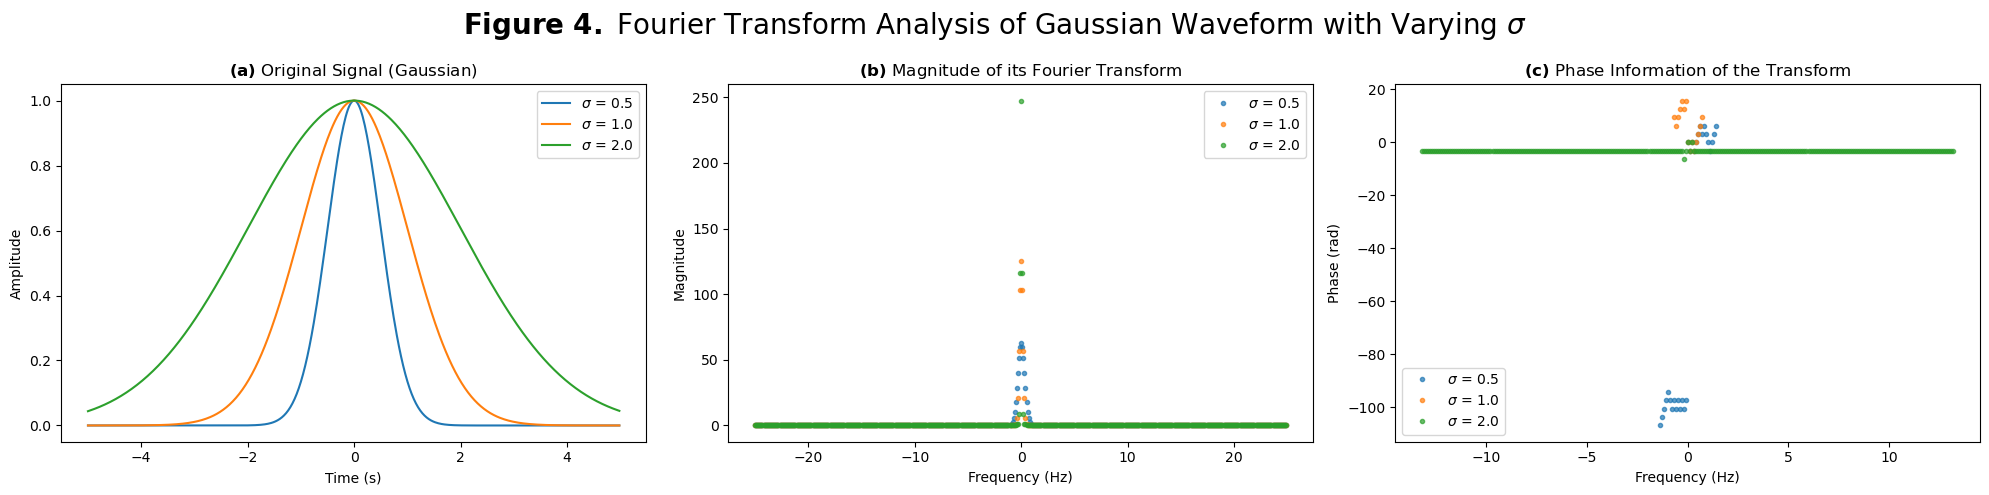

In [3]:
import numpy as np
import matplotlib.pyplot as plt
from scipy import signal

# Setting parameters
N = 500
t = np.linspace(-5, 5, N, endpoint=False)  # Centered time window works best for Gaussians
dt = t[1] - t[0]
freqs = np.fft.fftfreq(N, dt)

# Plotting into a 1x3 subplot
fig, ax = plt.subplots(1, 3, figsize=(20, 5))

# Defining sigma variations for the Gaussian function
sigmas = [0.5, 1.0, 2.0]

# Style dictionaries to distinguish each sigma variant
markers = {0.5: 'x', 1.0: 'o', 2.0: '.'}
sizes = {0.5: 35, 1.0: 20, 2.0: 10}
line_styles = {0.5: '-', 1.0: '--', 2.0: '-.'}

for sigma in sigmas:
    # 1. The Gaussian Signal with its Variations 
    nonsinu_signal = np.exp(-(t**2) / (2 * sigma**2))

    # 2. The Magnitude of its Fourier Transform 
    signal_ft = np.fft.fft(nonsinu_signal)
    mag_ft = np.abs(signal_ft)

    # 3. The Phase Information of the Transform (with unwrapping and noise masking)
    phase_ft_unwrapped = np.unwrap(np.angle(signal_ft))
    phase_ft_unwrapped[mag_ft < 1e-3] = np.nan # This is a noise-filtering mask that flags the signal that drops below too low and replaces the calculated phase angle with "Not a Number" (NaN), ensuring thet matplotlib ignores those values and leaves a blank space, producing a cleaner plot.

    # Plot each variation on the respective subplot
    ax[0].plot(t, nonsinu_signal, label=f'$\sigma$ = {sigma}')
    
    # # Plot (b) Magnitude: Using distinct markers and sizes
    # ax[1].scatter(freqs, mag_ft, marker=markers[sigma], s=sizes[sigma], alpha=0.7, label=f'$\sigma$ = {sigma}')
    ax[1].plot(freqs, mag_ft, ".", label=f'$\sigma$ = {sigma}', alpha=0.7)
    
    # Plot (c) Phase: Using distinct line styles
    # ax[2].plot(freqs, phase_ft_unwrapped, line_styles[sigma], linewidth=1.5, label=f'$\sigma$ = {sigma}', alpha=0.8)
    ax[2].plot(freqs, phase_ft_unwrapped, ".", label=f'$\sigma$ = {sigma}', alpha=0.7)

# Formatting Subplots 
ax[0].set_title(r"$\bf{(a)}$ Original Signal (Gaussian)")
ax[0].set_xlabel("Time (s)")
ax[0].set_ylabel("Amplitude")
ax[0].legend()

ax[1].set_title(r"$\bf{(b)}$ Magnitude of its Fourier Transform")
ax[1].set_xlabel("Frequency (Hz)")
ax[1].set_ylabel("Magnitude")
ax[1].legend()

ax[2].set_title(r"$\bf{(c)}$ Phase Information of the Transform")
ax[2].set_xlabel("Frequency (Hz)")
ax[2].set_ylabel("Phase (rad)")
ax[2].legend()

plt.suptitle(r"$\bf{Figure\ 4.}$ Fourier Transform Analysis of Gaussian Waveform with Varying $\sigma$", fontsize=20)

plt.tight_layout()
plt.savefig("gaussian.png", dpi=150)
plt.show()

### Problem 2: Signal Processing in 1D (Fill in the blanks/Code to get to the desired result)

Steps performed: 

1) Create a composite signal from multiple sinusoids with three frequencies, get fft of clean signal
2) Add noise (gaussian noise)
3) Add a window (Hann)
4) Get fft of the noisy signal
5) filter frequencies below a threshold
6) get the inverse fft
7) compare the result

Discussion: Try running the procedure with a lower number of N (N<25000). What does lowering N do to the original signal? Will I still be able to recover that original signal if I add the noise below? Is there a limit of N to which I can recover the signal well? Why? (Answer in ~3 sentences)


----
1. Create a composite signal from multiple sinusoids with three frequencies, get fft of clean signal

In [7]:
# Make a wave (cosine or sine) - you can do combo of waves
N = 25000
dt = 0.0002 #if spacing is 0.0002, then frequency is 5000 Hz 
t_ = np.arange(N)*dt
freqs = [130, 230, 180]
phase = [np.pi/3, np.pi/4, np.pi/6]

signal_original = np.sum([np.cos(2*np.pi*f*t_ + p) for f, p in zip(freqs, phase)], axis=0)

(0.0, 0.3)

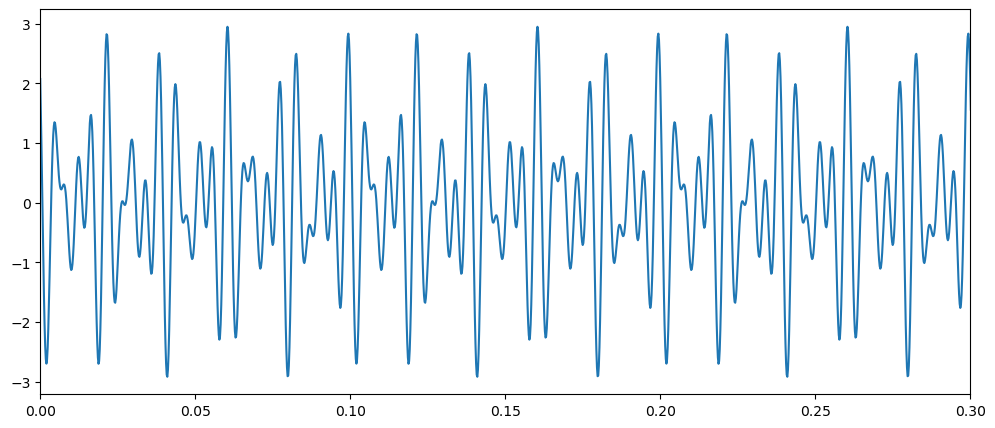

In [8]:
fig, ax = plt.subplots(figsize= (12,5))
ax.plot(t_, signal_original)
ax.set_xlim(0,0.3)

In [9]:
#FILL: Plot the fourier transform of the clean, original signal

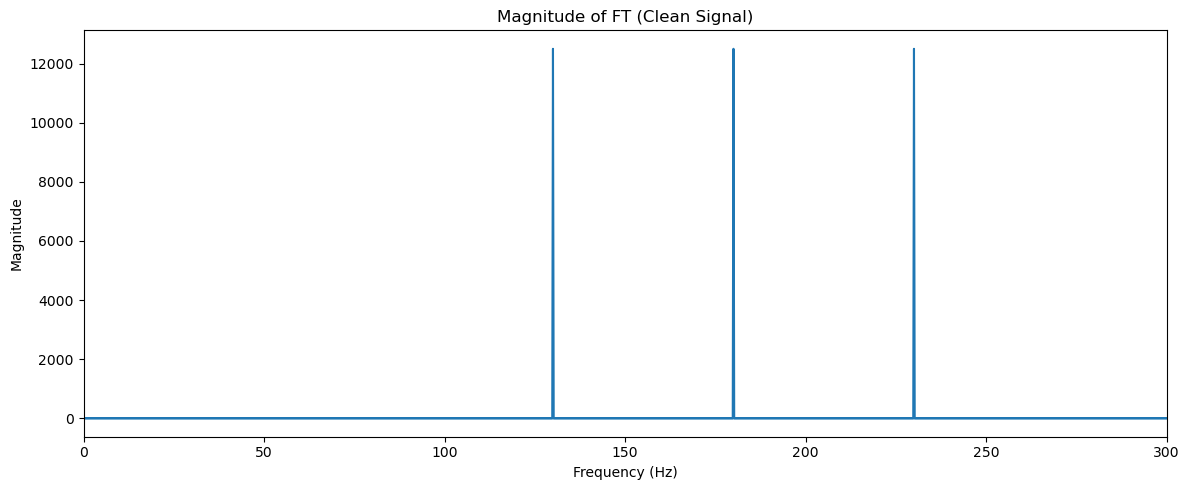

In [10]:
# Computing for the Fourier Transform of the clean, original signal
clean_ft = np.fft.fft(signal_original)
freqs = np.fft.fftfreq(N, dt)
mag_clean_ft = np.abs(clean_ft)

# Plotting
fig, ax = plt.subplots(figsize=(12, 5))

ax.plot(freqs, mag_clean_ft)
ax.set_title("Magnitude of FT (Clean Signal)")
ax.set_xlabel("Frequency (Hz)")
ax.set_ylabel("Magnitude")
ax.set_xlim(0, 300)

plt.tight_layout()
plt.show()

2. Add noise (gaussian noise)

In [11]:
rng = np.random.default_rng()

#Define parameters of Gaussian noise
mean = 0
std = 2

noise = rng.normal(loc = mean, scale = std, size = len(t_)) #Add noise to every data point

#Noisy data here
noisy_data = signal_original + noise*5

(0.0, 0.3)

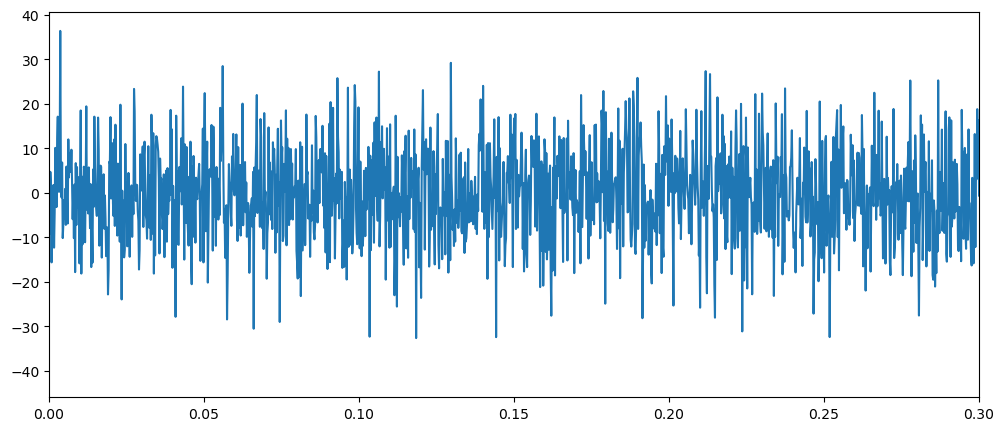

In [12]:
fig, ax = plt.subplots(figsize= (12,5))
ax.plot(t_, noisy_data)
ax.set_xlim(0,0.3)

3. Add a window (Hann)

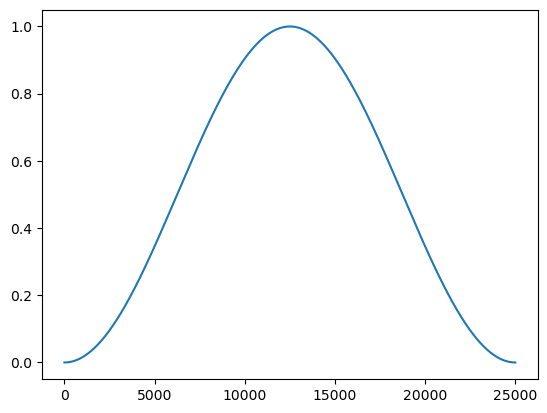

In [13]:
window = np.hanning(len(noisy_data)) #Create a window the size of the data length
plt.plot(window)

In [14]:
# Getting Fourier Transform of Hanning Window
windowSigPeaks = np.abs(np.fft.fftshift(np.fft.fft(window)))
windowSigFreqs = np.fft.fftshift(np.fft.fftfreq(N, dt))

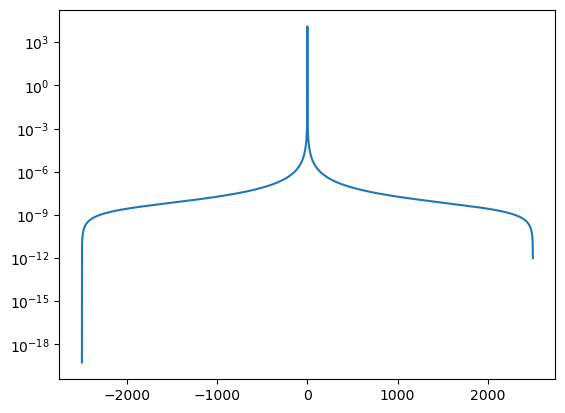

In [15]:
plt.plot(windowSigFreqs, windowSigPeaks)
plt.yscale('log')

In [16]:
noisyFourier = np.fft.fft(noisy_data*window)

# noisySigPeaks = np.abs(np.fft.fftshift(np.fft.fft(noisy_data*window)))

4. Get fft of the noisy signal

In [17]:
# Fill: Plot the magnitude of fourier transform of the noisy data multiplied by the hanning window

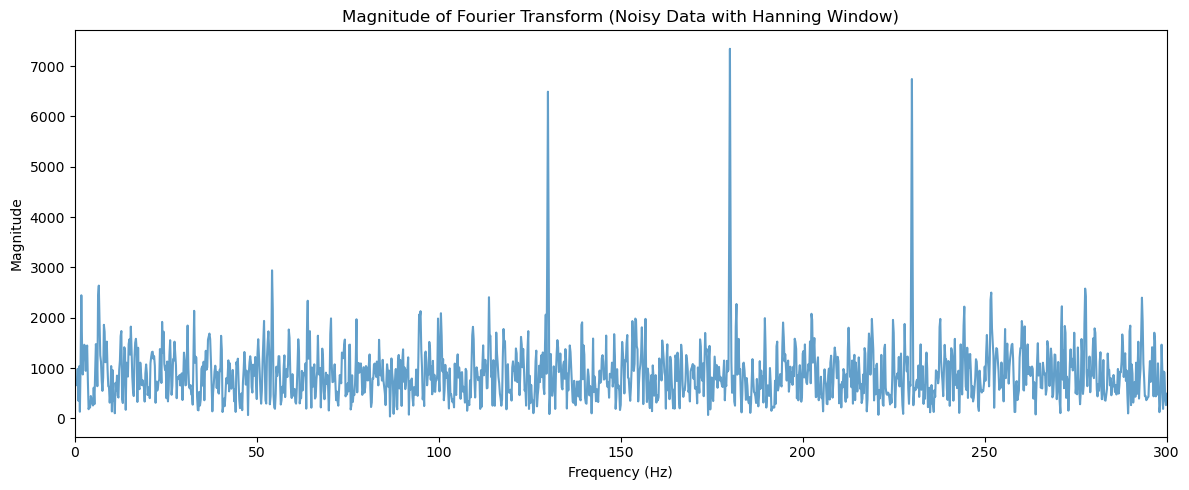

In [18]:
noisyFourier_mag = np.abs(np.fft.fftshift(noisyFourier)) 

fig, ax = plt.subplots(figsize=(12,5))

ax.plot(windowSigFreqs, noisyFourier_mag, alpha=0.7)
ax.set_title("Magnitude of Fourier Transform (Noisy Data with Hanning Window)")
ax.set_xlabel("Frequency (Hz)")
ax.set_ylabel("Magnitude")
ax.set_xlim(0, 300)

plt.tight_layout()
plt.show()

5. Filter frequencies below a threshold

In [19]:
# Fill: Find a suitable threshold value to filter the noise in fourier space

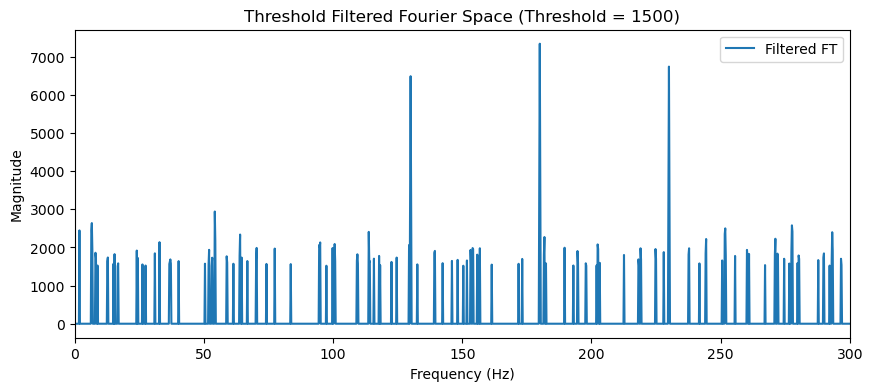

In [20]:
threshold = 1500

filtered_fft = np.where(np.abs(noisyFourier) > threshold, noisyFourier, 0)
filtered_fft_mag = np.abs(np.fft.fftshift(filtered_fft))

# Plotting
fig, ax = plt.subplots(figsize=(10, 4))

ax.plot(windowSigFreqs, filtered_fft_mag, label='Filtered FT')
ax.set_title(f"Threshold Filtered Fourier Space (Threshold = {threshold})")
ax.set_xlabel("Frequency (Hz)")
ax.set_ylabel("Magnitude")
ax.set_xlim(0, 300)

ax.legend()
plt.show()

6. Get the inverse fft

In [21]:
# Fill: with the cleaned signal in fourier space, convert it back to the time domain

In [22]:
recovered_signal = np.real(np.fft.ifft(filtered_fft))

7. Compare the result

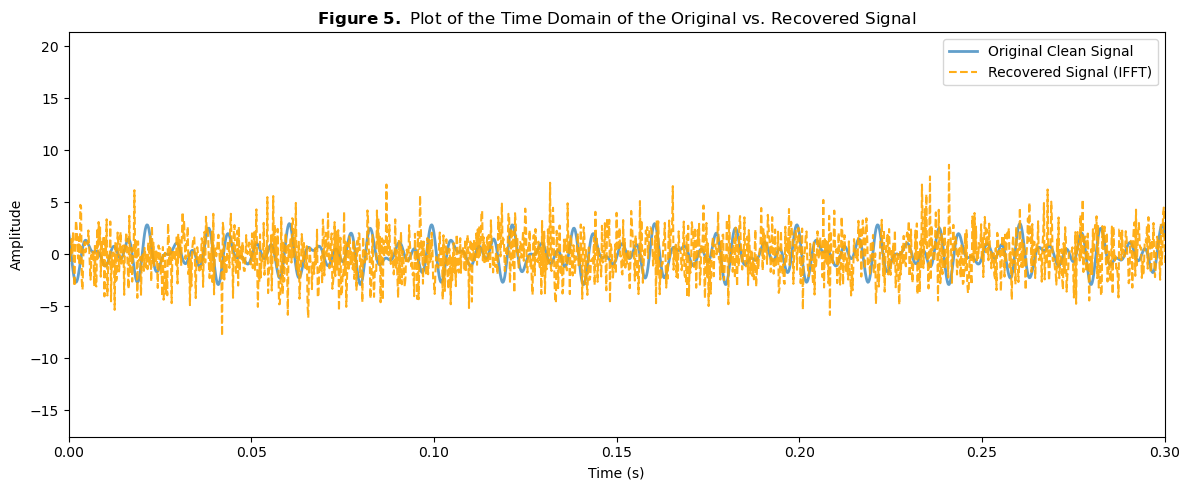

In [23]:
# Plotting the recovered signal
fig, ax = plt.subplots(figsize=(12, 5))

ax.plot(t_, signal_original, label='Original Clean Signal', alpha=0.7, linewidth=2)
ax.plot(t_, recovered_signal, label='Recovered Signal (IFFT)', linestyle='--', alpha=0.9, color='orange')

ax.set_title(r"$\bf{Figure\ 5.}$ Plot of the Time Domain of the Original vs. Recovered Signal")
ax.set_xlabel("Time (s)")
ax.set_ylabel("Amplitude")
ax.set_xlim(0, 0.3)  # Zoomed in to see the waveform overlay
ax.legend()

plt.tight_layout()
plt.savefig("orig_vs_recovered.png", dpi=150)
plt.show()

### Problem 3: Aliasing
1) Using different sampling frequencies (uniform sampling), generate a sinusoidal signal. Note the sampling frequencies, and the signal frequency. Use a sampling frequency above the Nyquist frequency, and another one below it.
3) Get their fourier transforms. Are they the same?
4) Plot: Show the fourier transform of an aliased signal, how it looks like in the time-domain, and how the actual signal looks like in the time domain if it's not aliased.
   
Discussion: Explain the report figure. Note the frequency of the signal you wanted to sample, the sampling frequencies used for the aliased and the non-aliased wave

---
1. Using different sampling frequencies (uniform sampling), generate a sinusoidal signal. Note the sampling frequencies, and the signal frequency. Use a sampling frequency above the Nyquist frequency, and another one below it.

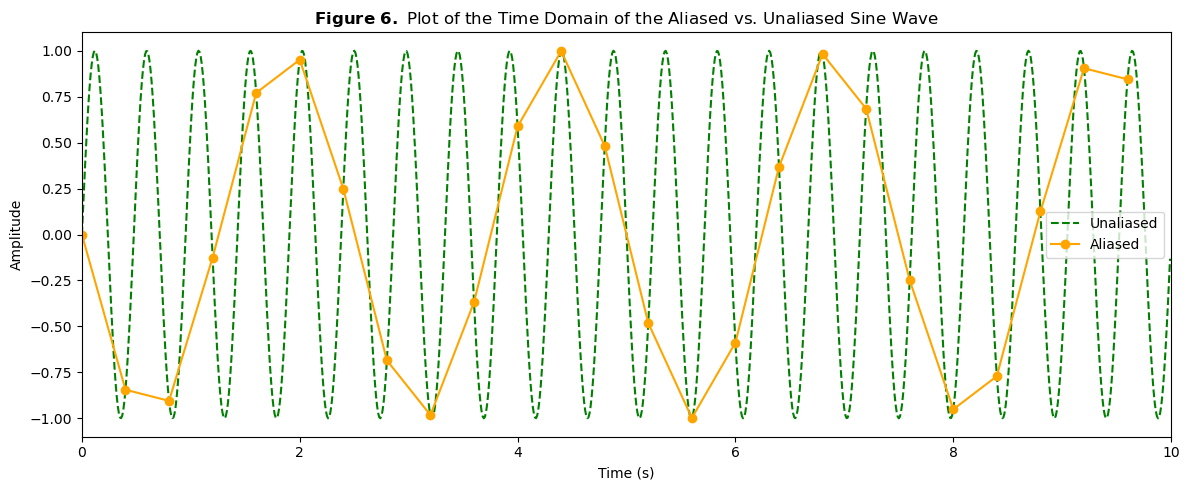

In [24]:
import numpy as np
import matplotlib.pyplot as plt
 
n_aliased = 25     
n_unaliased = 1000   
t = 10 # This is the total duration 
dt = t/n_aliased 
dt_un = t/n_unaliased

t_aliased = np.arange(n_aliased) * dt
t_unaliased = np.arange(n_unaliased) * dt_un

freq = 2.1  # Signal frequency 

def cont_signal(freq, time):
    return np.sin(2 * np.pi * freq * time)

discrete_signal = cont_signal(freq, t_aliased)
discrete_unaliased = cont_signal(freq, t_unaliased)

# Plotting
fig, ax = plt.subplots(figsize=(12,5))

ax.plot(t_unaliased, discrete_unaliased, color="green", linestyle='--', label="Unaliased")
ax.plot(t_aliased, discrete_signal, color="orange", marker='o', label="Aliased")
ax.set_xlim(0, 10)
ax.set_xlabel("Time (s)")
ax.set_ylabel("Amplitude")
ax.set_title(r"$\bf{Figure\ 6.}$ Plot of the Time Domain of the Aliased vs. Unaliased Sine Wave")
ax.legend()

plt.tight_layout()
plt.savefig("aliased_vs_unaliased.png", dpi=150)
plt.show()

2. Get their fourier transforms. Are they the same?
3. Plot: Show the fourier transform of an aliased signal, how it looks like in the time-domain, and how the actual signal looks like in the time domain if it's not aliased.

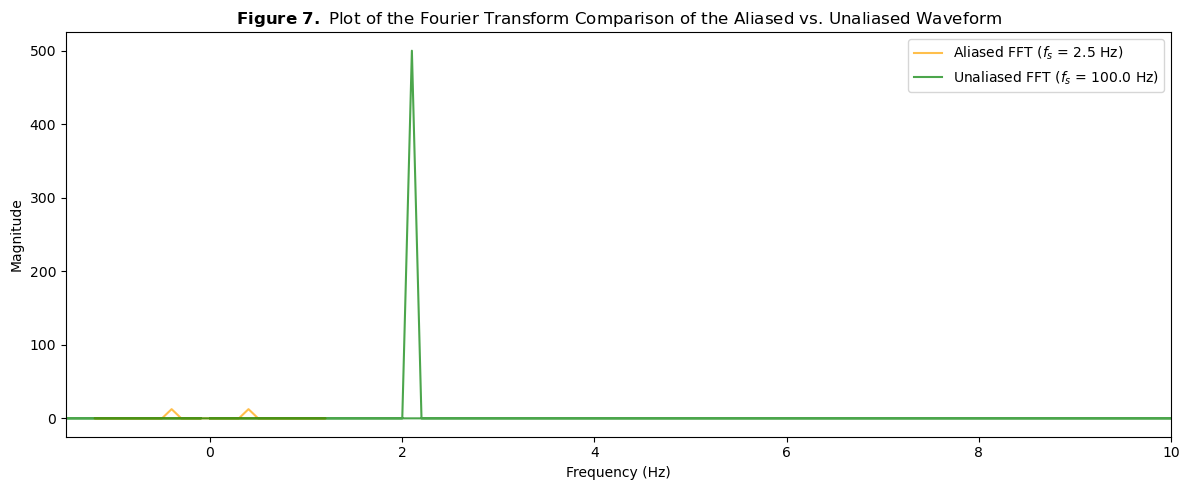

In [25]:
# Getting Fourier Transforms of Aliased and Unaliased
ft_aliased = np.fft.fft(discrete_signal)
freqs_aliased = np.fft.fftfreq(n_aliased, dt)
mag_aliased = np.abs(ft_aliased)

ft_unaliased = np.fft.fft(discrete_unaliased)
freqs_unaliased = np.fft.fftfreq(n_unaliased, dt_un)
mag_unaliased = np.abs(ft_unaliased)

# Plotting into a 1x2 subplot for comparison
fig, ax = plt.subplots(figsize=(12,5))

ax.plot(freqs_aliased, mag_aliased, color="orange", alpha=0.7, label=f"Aliased FFT ($f_s$ = {1/dt:.1f} Hz)")
ax.plot(freqs_unaliased, mag_unaliased, color="green", alpha=0.7, label=f"Unaliased FFT ($f_s$ = {1/dt_un:.1f} Hz)")

ax.set_ylabel("Magnitude")
ax.set_xlabel("Frequency (Hz)")
ax.set_xlim(-1.5, 10)
ax.set_title(r"$\bf{Figure\ 7.}$ Plot of the Fourier Transform Comparison of the Aliased vs. Unaliased Waveform")
ax.legend()

plt.tight_layout()
plt.savefig("ft_aliased_vs_unaliased.png", dpi=150)
plt.show()

#### Problem code summary

Include a brief summary (2–3 sentences) at the bottom of your code outlining the purpose of the script and its core algorithm. Focus on explaining why you wrote the code this way and the reasoning behind your implementation choices.

---

My script implements time-domain signal generation while varying parameters, Fast Fourier Transform (FFT) spectral analysis, and frequency-bin mapping to evaluate waveform (Triangle and Gaussian) scaling, sampling density limitations, and aliasing phenomena, utilizing the Nyquist Criterion. Vectorized NumPy operations and phase unwrapping features were utilized to ensure efficiency in computations and numerical stability across varying parameters. Specifically, time arrays are initialized using np.linspace, frequency bins are handled via np.fft.fftfreq, scipy.signal.sawtooth is used to generate clean non-sinusoidal waveforms for analysis, np.abs to get the magnitude, np.angle to get the phase, np.unwrap to maintain stability, and plotting them into subplot layouts for further comparison and analysis. 

---
## Section 3: Notes

In [15]:
import numpy as np
import matplotlib.pyplot as plt

### Fourier transform (from $t$-space to $\omega$-space)
$$ Y(\omega) = \int_{-\infty}^{+\infty} dt \frac{e^{-i\omega t}}{\sqrt{2\pi}}y(t)$$

### Inverse Fourier transform (from $\omega$-space to $t$-space)
$$ y(t) = \int_{-\infty}^{+\infty} d\omega Y(\omega) \frac{e^{i\omega t}}{\sqrt{2\pi}}$$

Something to think about: while we essentially do numerical integration, we do not impose h. Instead, we utilize the spacing of the dataset.

### Discrete FT/IFT

$$ Y_n = \frac{1}{\sqrt{2\pi}} \sum_{k=1}^N \left[(\cos(nk\theta)\Re\{y_k\}  +\sin(nk\theta)\Im\{y_k\} +i(\cos(nk\theta)\Im\{y_k\} −\sin(nk\theta)\Re\{y_k\})]\right]$$

$$ y_k = \frac{\sqrt{2\pi}}{N} \sum_{k=1}^N \left[(\cos(nk\theta)\Re\{Y_n\}  -\sin(nk\theta)\Im\{Y_n\} +i(\cos(nk\theta)\Im\{Y_n\} +\sin(nk\theta)\Re\{Y_n\})]\right]$$

Why bother it doing this way? 

It cleanly splits the real and imaginary part for both inputs and outputs, so that you can use a pair of floats rather than an aggregate complex data type (complex128 is just a pair of float64 anyway).

Using $Z=e^{−i\theta}, \rightarrow Z^{\pm nk} = e^{\mp ink\theta} = \cos(nk\theta)\mp i\sin(nk\theta)$.

(0.0, 4.0)

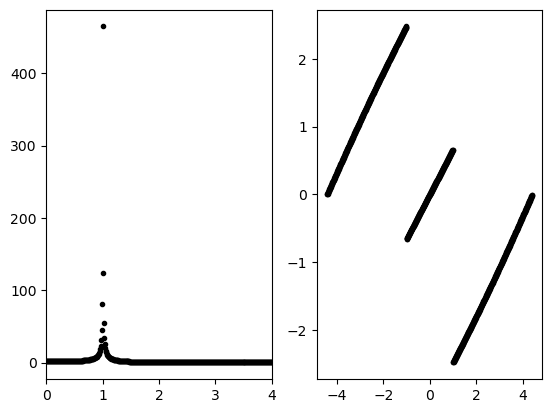

In [16]:
import numpy as np
import matplotlib.pyplot as plt

N = 1000
x = np.linspace(0, 18*2*np.pi, N)
deltaT = x[1] - x[0]

f = 1
y = np.cos(2*np.pi*f*x)

freqs = np.fft.fftfreq(N, deltaT)
Yk = np.fft.fft(y)

# # Q: Why do fftshift?
# Yk = np.fft.fftshift(Yk)

Yk_mag = np.abs(Yk)
Yk_phase = np.angle(Yk)
# Q: Why unwrap?
Yk_phase = np.unwrap(Yk_phase)

fig, ax = plt.subplots(1,2)

ax[0].plot(freqs, Yk_mag, "k.")
ax[1].plot(freqs, Yk_phase, "k.")
ax[0].set_xlim(0, 4)

### Waveforms of interest
- Sinusoid (single frequency, varying phase shift)
- Sum of sinusoids with different frequencies and phases
- Product of sinusoids with different frequencies and phases
- Square wave (both single and periodic)
- Triangle wave (sawtooth, ramp, reverse ramp)
- Gaussian function
- Finite-time sinusoid
- Gaussian wave packet

In [17]:
t = np.linspace(0,10,1000) #Create 100 pts from 0 to 10
x = np.sin(2*np.pi*2*t)

Text(0, 0.5, 'x')

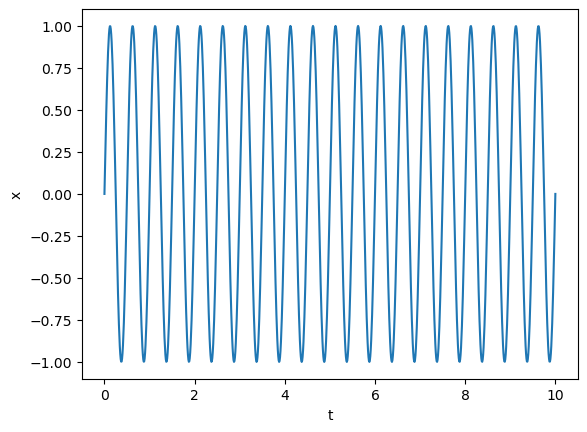

In [18]:
plt.plot(t,x)
plt.xlabel("t")
plt.ylabel("x")

In [19]:
x_ft = np.fft.fft(x)
np.fft.fftfreq?

Signature: np.fft.fftfreq(n, d=1.0)
Docstring:
Return the Discrete Fourier Transform sample frequencies.

The returned float array `f` contains the frequency bin centers in cycles
per unit of the sample spacing (with zero at the start).  For instance, if
the sample spacing is in seconds, then the frequency unit is cycles/second.

Given a window length `n` and a sample spacing `d`::

  f = [0, 1, ...,   n/2-1,     -n/2, ..., -1] / (d*n)   if n is even
  f = [0, 1, ..., (n-1)/2, -(n-1)/2, ..., -1] / (d*n)   if n is odd

Parameters
----------
n : int
    Window length.
d : scalar, optional
    Sample spacing (inverse of the sampling rate). Defaults to 1.

Returns
-------
f : ndarray
    Array of length `n` containing the sample frequencies.

Examples
--------
>>> signal = np.array([-2, 8, 6, 4, 1, 0, 3, 5], dtype=float)
>>> fourier = np.fft.fft(signal)
>>> n = signal.size
>>> timestep = 0.1
>>> freq = np.fft.fftfreq(n, d=timestep)
>>> freq
array([ 0.  ,  1.25,  2.5 , ..., -3.75, -2.5 , -1

### Plotting

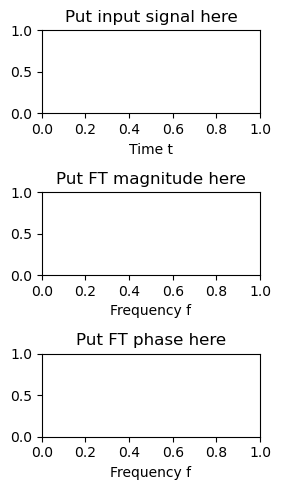

In [20]:
fig, ax = plt.subplots(3, 1, figsize=(3, 5))

ax[0].set_title("Put input signal here")
ax[0].set_xlabel("Time t")
#....
ax[1].set_title("Put FT magnitude here")
ax[1].set_xlabel("Frequency f")
#....
ax[2].set_title("Put FT phase here")
ax[2].set_xlabel("Frequency f")
#...

fig.tight_layout()

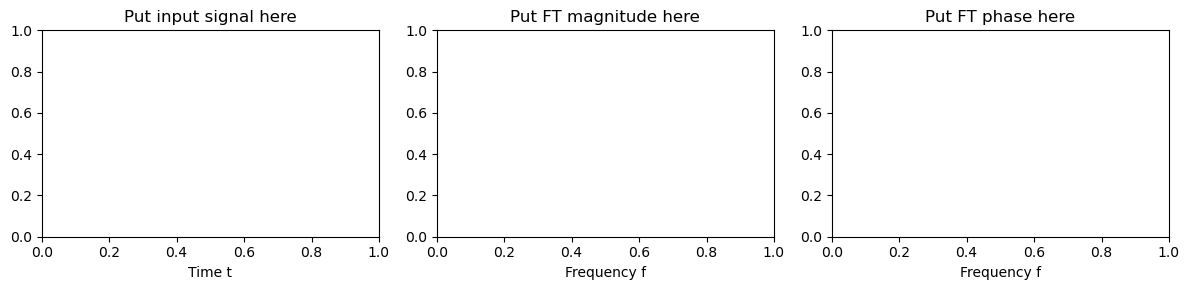

In [21]:
fig, ax = plt.subplots(1, 3, figsize=(12, 3))

ax[0].set_title("Put input signal here")
ax[0].set_xlabel("Time t")
#....
ax[1].set_title("Put FT magnitude here")
ax[1].set_xlabel("Frequency f")
#....
ax[2].set_title("Put FT phase here")
ax[2].set_xlabel("Frequency f")
#...

fig.tight_layout()

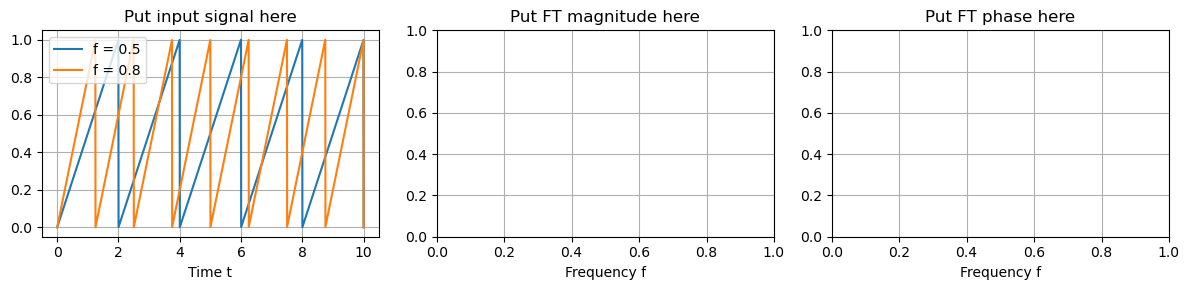

In [22]:
fig, axs = plt.subplots(1, 3, figsize=(12, 3))
ax_t, ax_f, ax_p = axs

t = np.linspace(0, 10, 2048)
f = 0.5 # Frequency
T = 1/(f) # Period
f2 = 0.8 # Frequency
T2 = 1/(f2) # Period


ax_t.set_title("Put input signal here")
ax_t.set_xlabel("Time t")
ax_t.plot(t, (t%T)/T, label="f = 0.5")
ax_t.plot(t, (t%T2)/T2, label="f = 0.8")
ax_t.legend()
#....
ax_f.set_title("Put FT magnitude here")
ax_f.set_xlabel("Frequency f")
#....
ax_p.set_title("Put FT phase here")
ax_p.set_xlabel("Frequency f")
#...


for ax in axs:
    ax.grid(True)
fig.tight_layout()

## 1-D convolution

In [23]:
a = [1,1,1,0,0,0,0,1,1,1,0,0,0,1,0,0,0,1,1,1,0,1,1,0,0,0,0]
v = [1,1,1]



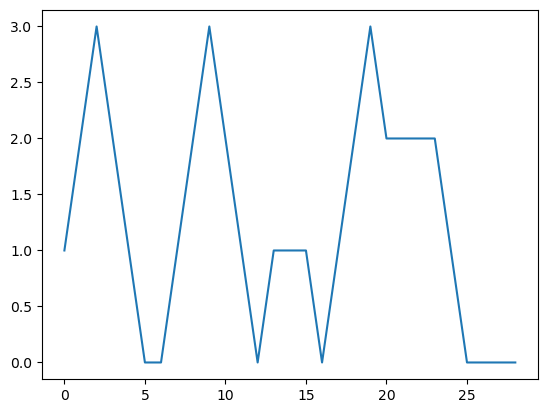

In [24]:
plt.plot(np.arange(len(np.convolve(a,v, mode='full'))), np.convolve(a,v, mode='full'))

### Convolution attempt (bringing circuits analogy) 

In [18]:
import numpy as np
from scipy import signal
import matplotlib.pyplot as plt
N = 500
t = np.linspace(0, 1, N, endpoint=False)
t_input = np.linspace(0, 5, N*5, endpoint=False)
signal_freq = 5
# dt = t[1] - t[0]
# nonsinu_signal = signal.square(2 * np.pi * signal_freq * t)

In [19]:
tau = 0.1
h_t = np.exp(-t/tau)
input_signal = signal.square(2 * np.pi * signal_freq * t_input) #cont_signal(t, freq)

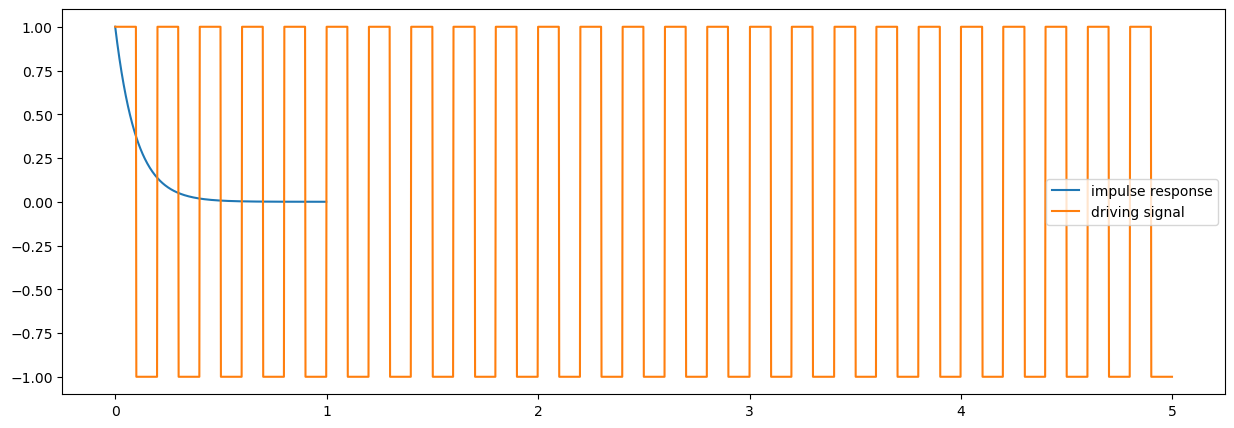

In [20]:
fig, ax = plt.subplots(figsize = (15,5))
ax.plot(t, h_t, label = "impulse response")
ax.plot(t_input, input_signal, label= "driving signal")
ax.legend()

In [21]:
response = np.convolve(input_signal, h_t, mode = "same")

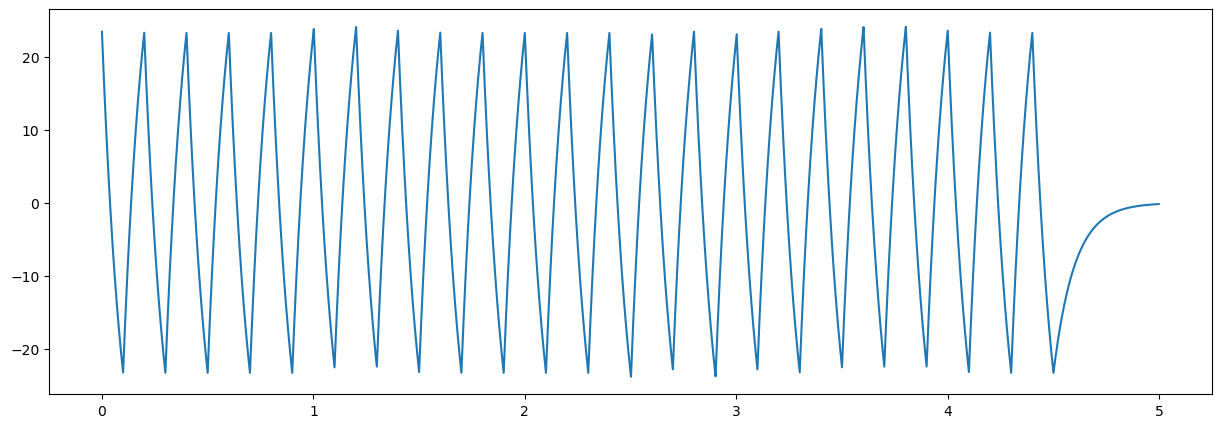

In [22]:
fig, ax = plt.subplots(figsize = (15,5))
#ax.plot(t, input_signal)
ax.plot(t_input, response)

In [23]:
fourier_length = len(h_t) + len(input_signal) - 1

In [24]:
fourier_input = np.fft.fft(input_signal, n = fourier_length)
fourier_h = np.fft.fft(h_t, n = fourier_length)

In [25]:
fourier_response = fourier_h*fourier_input 

In [26]:
response = np.real(np.fft.ifft(fourier_response))

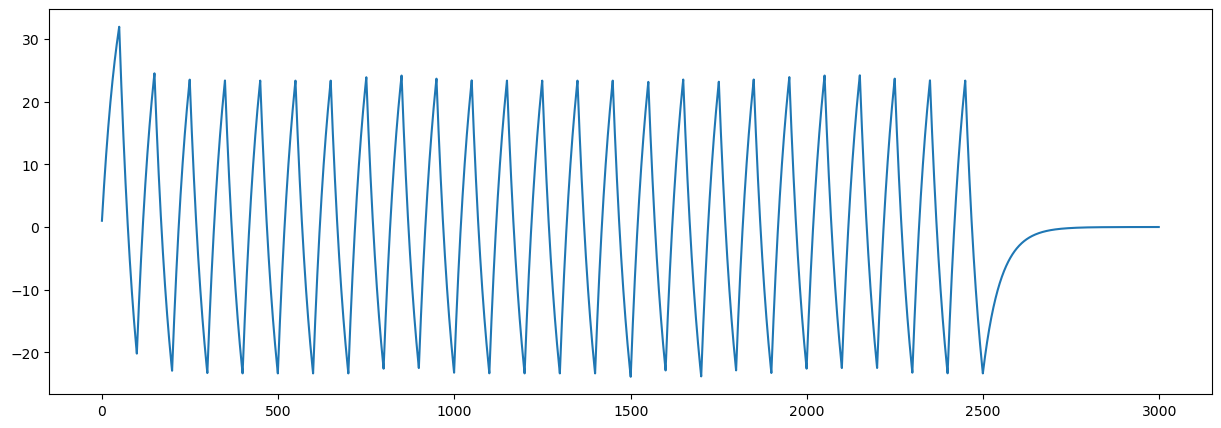

In [27]:
fig, ax = plt.subplots(figsize = (15,5))

ax.plot(response)